# 🦟 VectorIA
## Análisis Exploratorio de Datos (EDA)
### Dataset 3: AI Mosquito Alert Challenge Dataset 2023

**Proyecto:** VectorIA — Asistente Inteligente para la Vigilancia del Dengue en Costa Rica  
**Módulo:** CNN — Identificación de mosquitos  
**Fuente:** [Mosquito Alert / Zenodo](https://zenodo.org/records/15063886)  
**Licencia de origen:** CC BY-NC-SA 4.0

---

### Objetivo

Explorar las imágenes y las anotaciones del dataset Mosquito Alert, evaluar la distribución de especies, características de las fotografías, integridad de archivos, calidad visual, posibles duplicados y validez de las cajas delimitadoras (*bounding boxes*). El objetivo es identificar aspectos que deben considerarse antes del entrenamiento de la CNN.

**Alcance:** únicamente exploración de datos; no se entrena ningún modelo, no se eliminan archivos y no se modifican imágenes originales.

**Nota:** el conteo de **imágenes** no siempre coincide con el de **anotaciones**. El CSV puede registrar las etiquetas y coordenadas de los mosquitos en las fotografías.

## 1. Importación de librerías

Se importan las librerías utilizadas para recorrer carpetas, analizar datos, visualizar fotografías y medir su calidad. Se realiza una sola importación al inicio del notebook.

In [28]:
from pathlib import Path
from collections import defaultdict
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display
import cv2


## 2. Ubicación y estructura del dataset

Se utiliza la ruta de extracción definida para Mosquito Alert. La carpeta principal debe contener `images/` y `labels/`, además de los archivos descriptivos del dataset.

In [29]:
ruta = Path(r"C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\data\raw\mosquitos\mosquito_dataset_ai_v1")
carpeta_imagenes = ruta / "images"
carpeta_etiquetas = ruta / "labels"

print("Dataset:", ruta)
print("\nContenido principal:")
for elemento in sorted(ruta.iterdir()):
    print("[Carpeta]" if elemento.is_dir() else "[Archivo]", elemento.name)

Dataset: C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\data\raw\mosquitos\mosquito_dataset_ai_v1

Contenido principal:
[Archivo] dataset_description.pdf
[Carpeta] images
[Carpeta] labels
[Archivo] license.txt


## 3. Lectura y exploración de las anotaciones

Se carga el archivo `annotations.csv` de `labels/`. Contiene el nombre de la imagen, la etiqueta del mosquito y las coordenadas de la caja que lo delimita. Primero se inspeccionan sus columnas y sus valores, sin modificar el archivo.

In [30]:
archivos_csv = sorted(carpeta_etiquetas.rglob("*.csv"))
if not archivos_csv:
    raise FileNotFoundError("No se encontró un archivo CSV dentro de la carpeta labels/.")

csv_anotaciones = next(
    (p for p in archivos_csv if p.name.lower() == "annotations.csv"),
    archivos_csv[0]
)

anotaciones = pd.read_csv(csv_anotaciones)
requeridas = {
    "img_fName", "class_label", "img_w", "img_h",
    "bbx_xtl", "bbx_ytl", "bbx_xbr", "bbx_ybr"
}
faltantes = requeridas - set(anotaciones.columns)
if faltantes:
    raise ValueError(f"Faltan columnas de anotaciones: {sorted(faltantes)}")

print("CSV utilizado:", csv_anotaciones.name)
print("Anotaciones encontradas:", len(anotaciones))
print("Columnas:", anotaciones.columns.tolist())
display(anotaciones.head(10))
print("\nValores ausentes por columna:")
display(anotaciones.isna().sum().to_frame("Cantidad"))

CSV utilizado: annotations.csv
Anotaciones encontradas: 10357
Columnas: ['img_fName', 'img_w', 'img_h', 'bbx_xtl', 'bbx_ytl', 'bbx_xbr', 'bbx_ybr', 'class_label']


,img_fName,img_w,img_h,bbx_xtl,bbx_ytl,bbx_xbr,bbx_ybr,class_label
0,train_00000.jpeg,2448,3264,1301,1546,1641,2096,albopictus
1,train_00001.jpeg,3024,4032,900,1897,1950,2990,albopictus
2,train_00002.jpeg,768,1024,220,58,659,808,albopictus
3,train_00003.jpeg,3456,4608,1169,2364,1586,2826,albopictus
4,train_00004.jpeg,1024,1365,129,231,697,1007,culex
5,train_00005.jpeg,1152,2560,198,798,954,1351,albopictus
6,train_00006.jpeg,3072,4080,1104,1030,2458,2911,anopheles
7,train_00007.jpeg,2128,4608,248,728,2049,1992,albopictus
8,train_00008.jpeg,4000,2250,1768,899,2414,1591,albopictus
9,train_00009.jpeg,768,1024,180,140,683,744,albopictus



Valores ausentes por columna:


,Cantidad
img_fName,0
img_w,0
img_h,0
bbx_xtl,0
bbx_ytl,0
bbx_xbr,0
bbx_ybr,0
class_label,0


## 4. Inventario general de imágenes

Se enumeran las fotografías dentro de `images/`, incluyendo las posibles subcarpetas. Se registra la ruta, el nombre, la extensión y el tamaño del archivo.

In [31]:
extensiones = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}
archivos_imagen = sorted(
    p for p in carpeta_imagenes.rglob("*")
    if p.is_file() and p.suffix.lower() in extensiones
)
if not archivos_imagen:
    raise FileNotFoundError("No se encontraron imágenes dentro de images/.")

inventario = pd.DataFrame([
    {
        "Ruta": str(p),
        "Archivo": p.name,
        "Ruta relativa": p.relative_to(carpeta_imagenes).as_posix(),
        "Subcarpeta": p.parent.name,
        "Extensión": p.suffix.lower(),
        "Tamaño (MB)": p.stat().st_size / (1024 ** 2),
    }
    for p in archivos_imagen
])

print("Total de archivos de imagen:", len(inventario))
print("Espacio ocupado por las imágenes (GB):", round(inventario["Tamaño (MB)"].sum() / 1024, 2))
print("Subcarpetas principales de imágenes:")
display(inventario["Subcarpeta"].value_counts().head(15).to_frame("Imágenes"))
display(inventario.head(10))

Total de archivos de imagen: 10357
Espacio ocupado por las imágenes (GB): 9.84
Subcarpetas principales de imágenes:


,Imágenes
Subcarpeta,
images,10357


,Ruta,Archivo,Ruta relativa,Subcarpeta,Extensión,Tamaño (MB)
0,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,train_00000.jpeg,train_00000.jpeg,images,.jpeg,1.252006
1,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,train_00001.jpeg,train_00001.jpeg,images,.jpeg,1.213719
2,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,train_00002.jpeg,train_00002.jpeg,images,.jpeg,0.105976
3,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,train_00003.jpeg,train_00003.jpeg,images,.jpeg,2.980653
4,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,train_00004.jpeg,train_00004.jpeg,images,.jpeg,0.144897
5,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,train_00005.jpeg,train_00005.jpeg,images,.jpeg,0.531660
6,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,train_00006.jpeg,train_00006.jpeg,images,.jpeg,1.186769
7,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,train_00007.jpeg,train_00007.jpeg,images,.jpeg,1.270920
8,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,train_00008.jpeg,train_00008.jpeg,images,.jpeg,1.274738
9,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,train_00009.jpeg,train_00009.jpeg,images,.jpeg,0.107355


## 5. Asociación entre imágenes y etiquetas

Se relaciona `img_fName` con las fotografías existentes. Se diferencian **etiquetas sin archivo**, **imágenes sin etiqueta** y **nombres ambiguos**. No se deduce la especie a partir del nombre de la carpeta: la clase proviene del CSV oficial.

In [32]:
# Nombres de clases oficiales, mostrados de forma legible.
nombres_clases = {
    "aegypti": "Aedes aegypti",
    "albopictus": "Aedes albopictus",
    "anopheles": "Anopheles",
    "culex": "Culex",
    "culiseta": "Culiseta",
    "japonicus-koreicus": "Aedes japonicus/koreicus",
}

anotaciones["Etiqueta original"] = anotaciones["class_label"].astype("string").str.strip().str.lower()
anotaciones["Clase"] = anotaciones["Etiqueta original"].map(nombres_clases).fillna(
    anotaciones["Etiqueta original"]
)

# Índices de archivos para emparejar nombres sin cargar las imágenes en memoria.
por_ruta_relativa = {
    fila["Ruta relativa"].replace("\\", "/").lower(): fila["Ruta"]
    for _, fila in inventario.iterrows()
}
por_nombre = defaultdict(list)
for _, fila in inventario.iterrows():
    por_nombre[fila["Archivo"].lower()].append(fila["Ruta"])


def asociar_imagen(nombre):
    if pd.isna(nombre):
        return None, "Nombre ausente"
    referencia = str(nombre).strip().replace("\\", "/").lstrip("./").lower()
    referencia = referencia.removeprefix("images/")

    if referencia in por_ruta_relativa:
        return por_ruta_relativa[referencia], "Ruta relativa"

    coincidencias = por_nombre.get(referencia.rsplit("/", 1)[-1], [])
    if len(coincidencias) == 1:
        return coincidencias[0], "Nombre único"
    if len(coincidencias) > 1:
        return None, "Nombre ambiguo"
    return None, "Archivo no encontrado"

asociaciones = anotaciones["img_fName"].apply(asociar_imagen)
anotaciones["Ruta"] = asociaciones.apply(lambda x: x[0])
anotaciones["Estado asociación"] = asociaciones.apply(lambda x: x[1])

clases_por_ruta = (
    anotaciones.dropna(subset=["Ruta"])
    .groupby("Ruta")["Clase"]
    .agg(lambda s: ", ".join(sorted(set(s.dropna()))))
)
inventario["Clase"] = inventario["Ruta"].map(clases_por_ruta).fillna("Sin etiqueta")

print("Anotaciones asociadas a imágenes:", anotaciones["Ruta"].notna().sum())
print("Anotaciones sin imagen asociada:", anotaciones["Ruta"].isna().sum())
print("Imágenes sin anotación:", (inventario["Clase"] == "Sin etiqueta").sum())
display(anotaciones["Estado asociación"].value_counts().to_frame("Cantidad"))

Anotaciones asociadas a imágenes: 10357
Anotaciones sin imagen asociada: 0
Imágenes sin anotación: 0


,Cantidad
Estado asociación,
Ruta relativa,10357


## 6. Cantidad de imágenes y anotaciones por especie

Se cuentan tanto las filas del CSV como las fotografías únicas correspondientes a cada clase. Separar ambos conteos evita confundir las anotaciones con archivos de imagen.

In [33]:
tabla_conteo = (
    anotaciones.groupby("Clase", dropna=False)
    .agg(
        Anotaciones=("img_fName", "size"),
        **{"Imágenes únicas": ("Ruta", lambda s: s.dropna().nunique())}
    )
    .reset_index()
    .sort_values("Anotaciones", ascending=False)
)

display(tabla_conteo)
print("Total de anotaciones:", int(tabla_conteo["Anotaciones"].sum()))
print("Total de fotografías encontradas:", len(inventario))

,Clase,Anotaciones,Imágenes únicas
1,Aedes albopictus,4612,4612
4,Culex,4563,4563
5,Culiseta,622,622
2,Aedes japonicus/koreicus,429,429
3,Anopheles,84,84
0,Aedes aegypti,47,47


Total de anotaciones: 10357
Total de fotografías encontradas: 10357


## 7. Distribución porcentual de clases

Se calculan los porcentajes por **anotación**, con una comparación gráfica de la presencia de especies. La distribución puede evidenciar un desbalance importante para la CNN.

,Clase,Anotaciones,Imágenes únicas,Porcentaje de anotaciones (%)
1,Aedes albopictus,4612,4612,44.53
4,Culex,4563,4563,44.06
5,Culiseta,622,622,6.01
2,Aedes japonicus/koreicus,429,429,4.14
3,Anopheles,84,84,0.81
0,Aedes aegypti,47,47,0.45


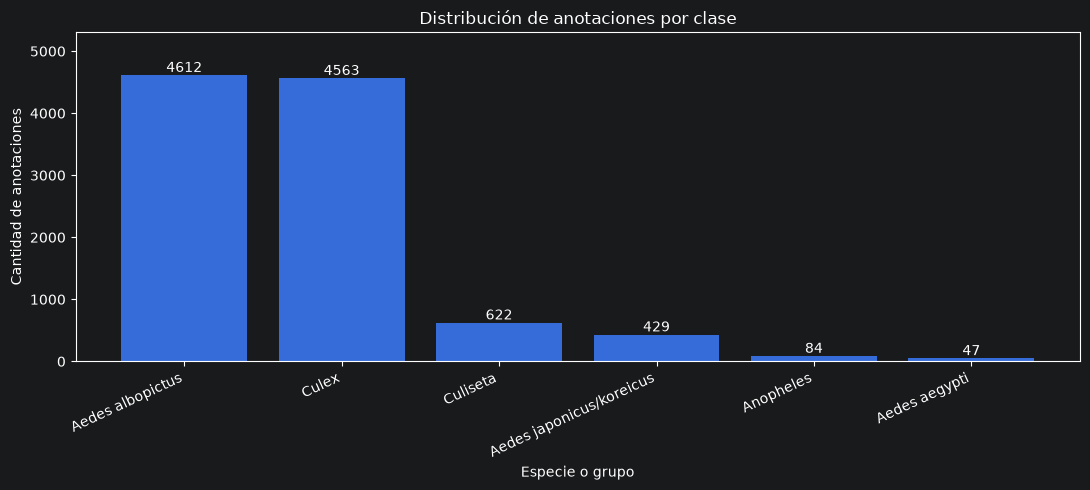

In [34]:
tabla_conteo["Porcentaje de anotaciones (%)"] = (
    tabla_conteo["Anotaciones"] / len(anotaciones) * 100
).round(2)
display(tabla_conteo)

plt.figure(figsize=(11, 5))
barras = plt.bar(tabla_conteo["Clase"], tabla_conteo["Anotaciones"])
for barra in barras:
    plt.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
             str(int(barra.get_height())), ha="center", va="bottom")
plt.xlabel("Especie o grupo")
plt.ylabel("Cantidad de anotaciones")
plt.title("Distribución de anotaciones por clase")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, tabla_conteo["Anotaciones"].max() * 1.15)
plt.tight_layout()
plt.show()

## 8. Visualización de imágenes por especie

Se presentan ejemplos de cada clase identificada. La muestra es reproducible y permite observar el mosquito, el fondo y posibles variaciones visuales entre imágenes.

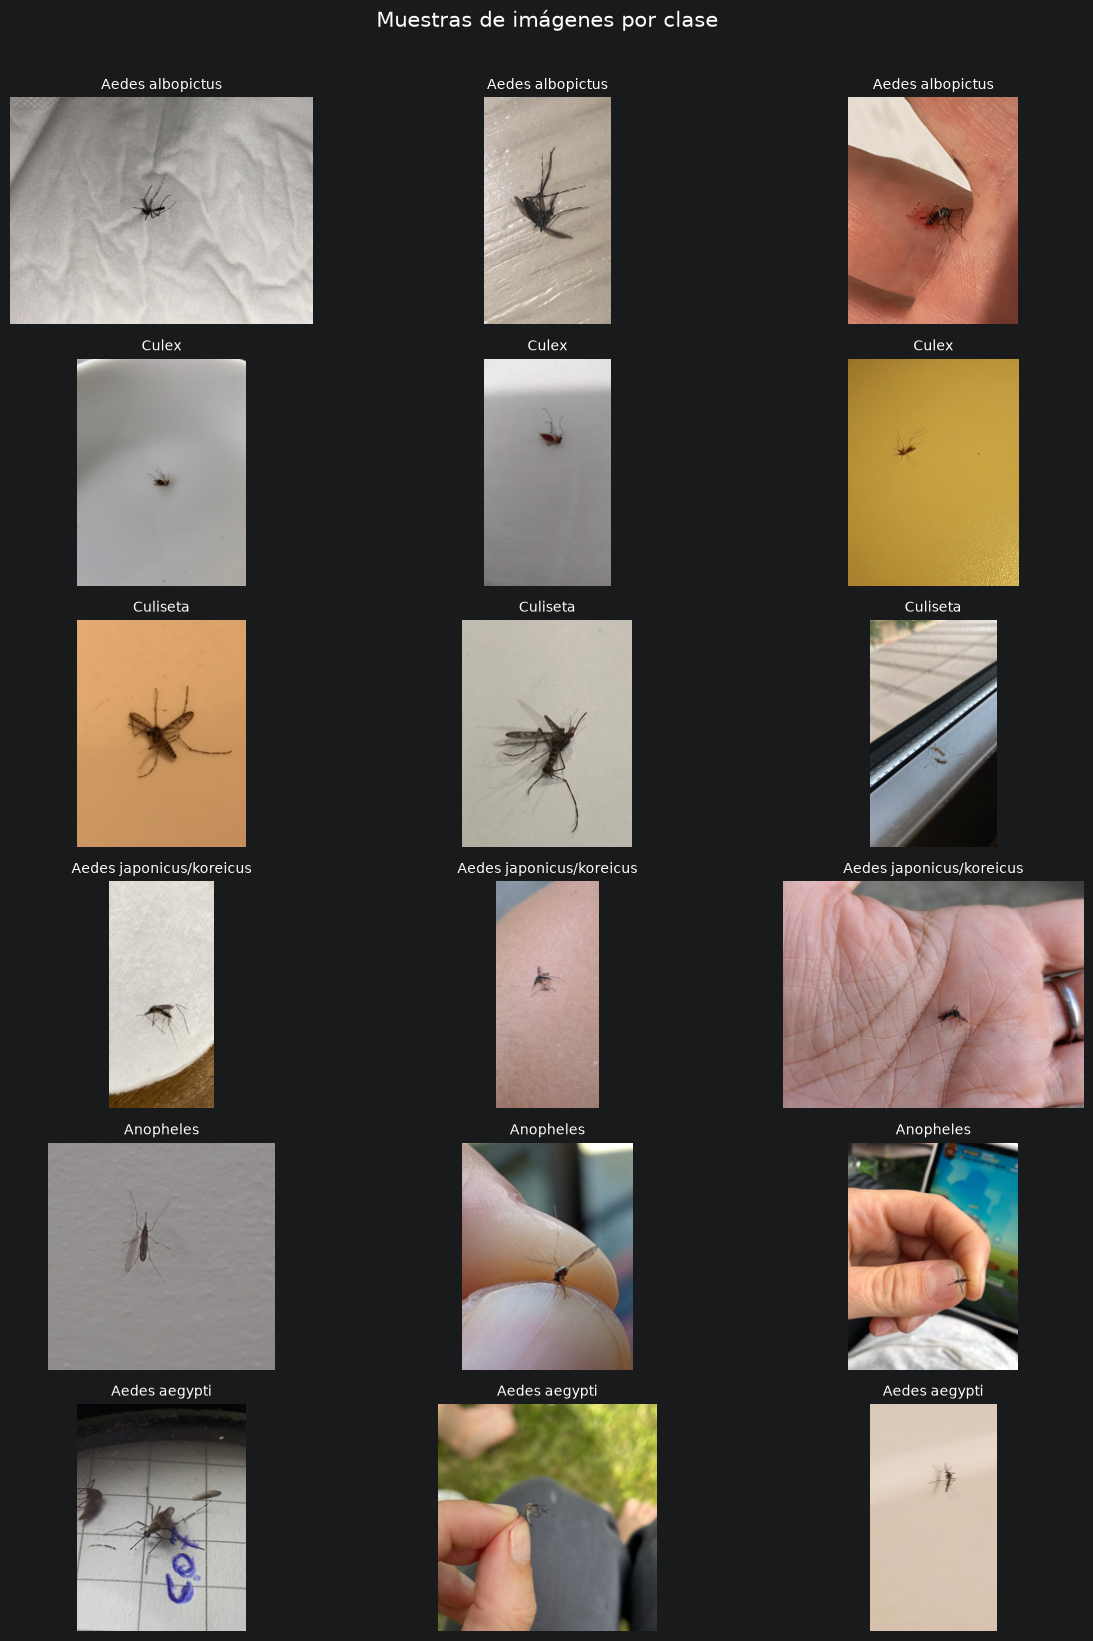

In [35]:
clases = tabla_conteo["Clase"].dropna().tolist()
columnas = 3
fig, ejes = plt.subplots(len(clases), columnas, figsize=(13, max(3, len(clases) * 2.7)), squeeze=False)

for fila, clase in enumerate(clases):
    rutas_clase = (
        anotaciones.loc[(anotaciones["Clase"] == clase) & anotaciones["Ruta"].notna(), "Ruta"]
        .drop_duplicates().sample(frac=1, random_state=42).head(columnas).tolist()
    )
    for col, eje in enumerate(ejes[fila]):
        eje.axis("off")
        if col < len(rutas_clase):
            with Image.open(rutas_clase[col]) as img:
                imagen = ImageOps.exif_transpose(img).convert("RGB")
                imagen.thumbnail((320, 230))
                eje.imshow(imagen)
            eje.set_title(clase, fontsize=10)

plt.suptitle("Muestras de imágenes por clase", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

## 9. Integridad, dimensiones y métricas básicas de calidad

Se leen las imágenes para registrar metadatos y evaluar su integridad. En esta misma pasada se calculan **brillo, contraste, nitidez y hash perceptual** a partir de versiones reducidas de 128 × 128 píxeles para evitar releer miles de imágenes en cada análisis posterior.

**Importante:** las métricas de nitidez y luz son aproximaciones calculadas sobre miniaturas; no sustituyen una revisión visual. La inspección puede tardar al tratarse de imágenes originales de gran tamaño.

In [36]:
registros = []
for numero, (_, fila) in enumerate(inventario.iterrows(), start=1):
    registro = {
        "Ruta": fila["Ruta"],
        "Ancho": np.nan,
        "Alto": np.nan,
        "Formato real": None,
        "Modo de color": None,
        "Canales": np.nan,
        "Brillo": np.nan,
        "Contraste": np.nan,
        "Nitidez": np.nan,
        "dHash": None,
        "Error": None,
    }
    try:
        with Image.open(fila["Ruta"]) as img:
            registro["Ancho"], registro["Alto"] = img.size
            registro["Formato real"] = img.format
            registro["Modo de color"] = img.mode
            registro["Canales"] = len(img.getbands())

            # Reducir el coste de decodificación de JPEG grandes.
            if img.format == "JPEG":
                img.draft("L", (256, 256))
            miniatura = ImageOps.exif_transpose(img).convert("L")
            miniatura.thumbnail((256, 256))
            miniatura = miniatura.resize((128, 128))
            pixeles = np.asarray(miniatura, dtype=np.uint8)

            registro["Brillo"] = float(pixeles.mean())
            registro["Contraste"] = float(pixeles.std())
            registro["Nitidez"] = float(cv2.Laplacian(pixeles, cv2.CV_64F).var())

            pequeno = np.asarray(miniatura.resize((9, 8)), dtype=np.int16)
            bits = pequeno[:, 1:] > pequeno[:, :-1]
            registro["dHash"] = "".join("1" if bit else "0" for bit in bits.ravel())
    except Exception as error:
        registro["Error"] = str(error)

    registros.append(registro)
    if numero % 2000 == 0:
        print(f"Imágenes analizadas: {numero} de {len(inventario)}")

df_meta = inventario.merge(pd.DataFrame(registros), on="Ruta", how="left")
df_validas = df_meta[df_meta["Error"].isna()].copy()
df_danadas = df_meta[df_meta["Error"].notna()].copy()

print("Imágenes revisadas:", len(df_meta))
print("Imágenes válidas:", len(df_validas))
print("Imágenes dañadas:", len(df_danadas))
display(df_danadas[["Ruta", "Error"]].head(15))

Imágenes analizadas: 2000 de 10357
Imágenes analizadas: 4000 de 10357
Imágenes analizadas: 6000 de 10357


C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\.venv\Lib\site-packages\PIL\Image.py:3593: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Imágenes analizadas: 8000 de 10357
Imágenes analizadas: 10000 de 10357
Imágenes revisadas: 10357
Imágenes válidas: 10357
Imágenes dañadas: 0


,Ruta,Error


## 10. Análisis de dimensiones de las imágenes

Se analizan los anchos y altos originales por clase para conocer la variabilidad dimensional y orientar el redimensionamiento previo al entrenamiento.

Ancho                                           \
                           count     mean      std    min     25%     50%   
Clase                                                                       
Aedes aegypti               47.0  2031.98  1061.01  454.0  1080.0  1788.0   
Aedes albopictus          4612.0  2186.64  1182.26  139.0  1055.0  2250.0   
Aedes japonicus/koreicus   429.0  2211.38  1144.40  352.0  1136.0  2084.0   
Anopheles                   84.0  1663.62  1066.22  750.0   768.0  1024.0   
Culex                     4563.0  1875.15  1149.96  228.0   960.0  1365.0   
Culiseta                   622.0  2090.54  1167.48  240.0  1024.0  1944.0   

                                            Alto                           \
                             75%     max   count     mean      std    min   
Clase                                                                       
Aedes aegypti             3024.0  4128.0    47.0  2456.60  1406.65  303.0   
Aedes albopictus          3024.0  9280.0  4612.0  2588.30  1356.34  106.0   
Aedes japonicus/koreicus  3024.0  6000.0   429.0  2745.90  1396.77  371.0   
Anopheles                 2500.0  4608.0    84.0  2276.30  1307.42  750.0   
Culex                     3024.0  6936.0  4563.0  2311.33  1334.76  169.0   
Culiseta                  3024.0  6936.0   622.0  2601.88  1380.15  320.0   

                                                            
                              25%     50%     75%      max  
Clase                                                       
Aedes aegypti             1200.00  2092.0  4032.0   5312.0  
Aedes albopictus          1318.75  2560.0  4000.0  12000.0  
Aedes japonicus/koreicus  1365.00  2592.0  4032.0   8000.0  
Anopheles                 1024.00  1600.0  4000.0   4608.0  
Culex                     1024.00  1820.0  4000.0   9248.0  
Culiseta                  1200.00  2273.0  4032.0   9248.0

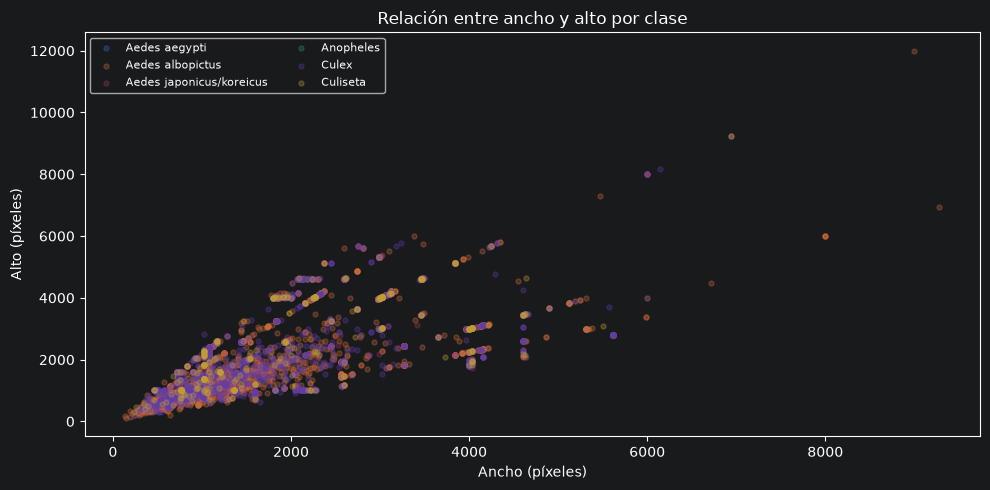

In [37]:
display(df_validas.groupby("Clase")[["Ancho", "Alto"]].describe().round(2))

plt.figure(figsize=(10, 5))
for clase, grupo in df_validas.groupby("Clase"):
    plt.scatter(grupo["Ancho"], grupo["Alto"], alpha=0.30, s=13, label=clase)
plt.xlabel("Ancho (píxeles)")
plt.ylabel("Alto (píxeles)")
plt.title("Relación entre ancho y alto por clase")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 11. Resoluciones y proporciones de aspecto

Se identifican las resoluciones más comunes y se analiza la relación entre ancho y alto de las fotografías.

Resoluciones diferentes: 2116


,Ancho,Alto,Cantidad
1967,3024,4032,1405
466,768,1024,1208
819,1024,1365,687
1956,3000,4000,456
1870,2448,3264,303
1259,1365,1024,217
2052,4032,3024,211
826,1024,1820,175
1097,1200,1600,151
1980,3120,4160,145


,count,mean,std,min,25%,50%,75%,max
Clase,,,,,,,,
Aedes aegypti,47.0,0.91,0.35,0.45,0.75,0.75,1.22,1.78
Aedes albopictus,4612.0,0.91,0.37,0.44,0.75,0.75,1.03,2.88
Aedes japonicus/koreicus,429.0,0.87,0.35,0.45,0.75,0.75,0.99,2.33
Anopheles,84.0,0.75,0.23,0.45,0.70,0.75,0.75,1.78
Culex,4563.0,0.85,0.34,0.36,0.75,0.75,0.75,2.65
Culiseta,622.0,0.85,0.34,0.45,0.75,0.75,0.75,2.22


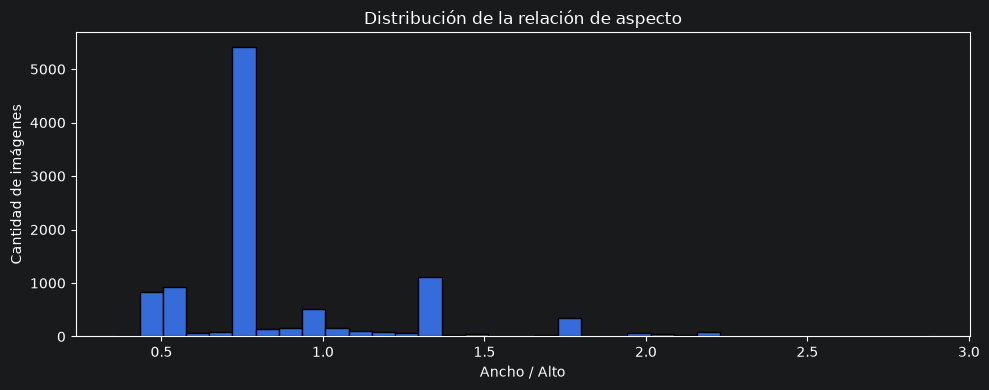

In [38]:
resoluciones = (
    df_validas.groupby(["Ancho", "Alto"]).size()
    .reset_index(name="Cantidad").sort_values("Cantidad", ascending=False)
)
df_validas["Relación de aspecto"] = df_validas["Ancho"] / df_validas["Alto"]

print("Resoluciones diferentes:", len(resoluciones))
display(resoluciones.head(15))
display(df_validas.groupby("Clase")["Relación de aspecto"].describe().round(2))

plt.figure(figsize=(10, 4))
plt.hist(df_validas["Relación de aspecto"], bins=35, edgecolor="black")
plt.title("Distribución de la relación de aspecto")
plt.xlabel("Ancho / Alto")
plt.ylabel("Cantidad de imágenes")
plt.tight_layout()
plt.show()

## 12. Análisis de formatos de archivos

Se comparan las extensiones declaradas con los formatos reconocidos por Pillow. Se identifican archivos con extensiones incompatibles con su formato real.

In [39]:
display(pd.crosstab(df_validas["Formato real"], df_validas["Clase"], margins=True))
display(df_validas["Extensión"].value_counts().to_frame("Cantidad"))

formatos_extensiones = {
    "JPEG": {".jpg", ".jpeg"},
    "PNG": {".png"},
    "WEBP": {".webp"},
    "BMP": {".bmp"},
    "TIFF": {".tif", ".tiff"},
}
inconsistencias_formato = df_validas[
    df_validas.apply(
        lambda f: f["Extensión"] not in formatos_extensiones.get(f["Formato real"], {f["Extensión"]}),
        axis=1,
    )
]
print("Archivos con extensión y formato inconsistentes:", len(inconsistencias_formato))
display(inconsistencias_formato[["Archivo", "Extensión", "Formato real"]].head(10))

Clase,Aedes aegypti,Aedes albopictus,Aedes japonicus/koreicus,Anopheles,Culex,Culiseta,All
Formato real,,,,,,,
JPEG,47,4612,429,84,4563,622,10357
All,47,4612,429,84,4563,622,10357


,Cantidad
Extensión,
.jpeg,10357


Archivos con extensión y formato inconsistentes: 0


,Archivo,Extensión,Formato real


## 13. Modos y canales de color

Se identifica si las fotografías están en RGB, RGBA, escala de grises u otros modos; también se cuenta el número de canales de cada imagen.

Clase,Aedes aegypti,Aedes albopictus,Aedes japonicus/koreicus,Anopheles,Culex,Culiseta,All
Modo de color,,,,,,,
RGB,47,4612,429,84,4563,622,10357
All,47,4612,429,84,4563,622,10357


,Cantidad
Canales,
3,10357


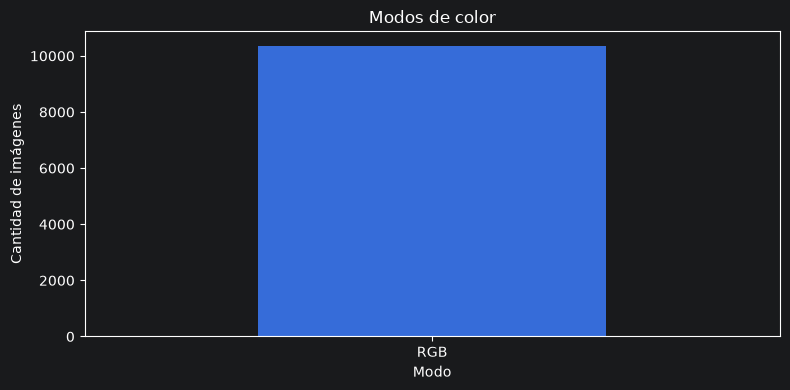

In [40]:
display(pd.crosstab(df_validas["Modo de color"], df_validas["Clase"], margins=True))
display(df_validas["Canales"].value_counts().sort_index().to_frame("Cantidad"))

plt.figure(figsize=(8, 4))
df_validas["Modo de color"].value_counts().plot(kind="bar")
plt.title("Modos de color")
plt.xlabel("Modo")
plt.ylabel("Cantidad de imágenes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 14. Análisis de tamaño de los archivos

Se examina el peso de las imágenes originales para identificar diferencias extremas entre archivos. El peso no mide directamente la calidad de la fotografía.

,count,mean,std,min,25%,50%,75%,max
Clase,,,,,,,,
Aedes aegypti,47.0,0.86,0.82,0.03,0.27,0.50,1.31,3.67
Aedes albopictus,4612.0,1.00,1.02,0.01,0.20,0.71,1.52,14.56
Aedes japonicus/koreicus,429.0,1.24,1.06,0.03,0.26,1.12,2.01,5.49
Anopheles,84.0,0.80,0.93,0.04,0.11,0.22,1.50,3.42
Culex,4563.0,0.90,1.04,0.01,0.13,0.34,1.55,12.64
Culiseta,622.0,1.13,1.09,0.02,0.17,0.79,1.88,5.05


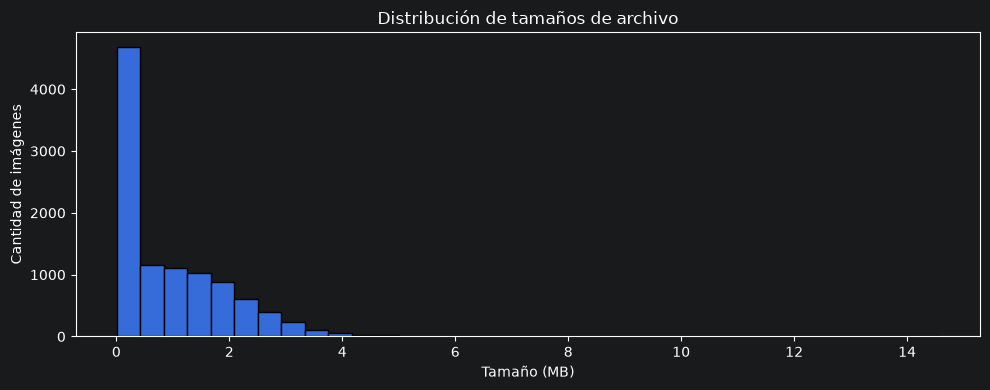

In [41]:
display(df_validas.groupby("Clase")["Tamaño (MB)"].describe().round(2))

plt.figure(figsize=(10, 4))
plt.hist(df_validas["Tamaño (MB)"], bins=35, edgecolor="black")
plt.title("Distribución de tamaños de archivo")
plt.xlabel("Tamaño (MB)")
plt.ylabel("Cantidad de imágenes")
plt.tight_layout()
plt.show()

## 15. Estadísticas de brillo y contraste

El **brillo** se estima mediante la media de intensidad de píxeles en escala de grises (0–255). El **contraste** se aproxima con su desviación estándar. Las métricas se calcularon en el punto 9 sobre miniaturas.

In [42]:
display(df_validas.groupby("Clase")[["Brillo", "Contraste"]].describe().round(2))
print("Brillo medio general:", round(df_validas["Brillo"].mean(), 2))
print("Contraste medio general:", round(df_validas["Contraste"].mean(), 2))

Brillo                                        \
                           count    mean    std    min     25%     50%   
Clase                                                                    
Aedes aegypti               47.0  153.21  36.05  95.23  125.87  150.55   
Aedes albopictus          4612.0  148.00  29.46  35.98  130.01  148.25   
Aedes japonicus/koreicus   429.0  147.87  27.50  28.04  131.23  147.61   
Anopheles                   84.0  154.76  25.67  78.43  141.58  154.88   
Culex                     4563.0  152.25  28.16  36.26  135.76  154.14   
Culiseta                   622.0  150.63  28.95  63.09  133.13  151.78   

                                         Contraste                             \
                             75%     max     count   mean    std   min    25%   
Clase                                                                           
Aedes aegypti             175.20  236.56      47.0  41.17  16.08  8.31  29.24   
Aedes albopictus          166.65  254.38    4612.0  34.68  17.14  4.16  20.93   
Aedes japonicus/koreicus  165.77  218.48     429.0  36.98  17.24  8.40  23.21   
Anopheles                 170.77  237.27      84.0  30.05  17.37  4.48  15.54   
Culex                     170.33  253.45    4563.0  30.11  18.10  2.96  15.66   
Culiseta                  168.88  242.96     622.0  34.38  17.30  6.53  21.07   

                                               
                            50%    75%    max  
Clase                                          
Aedes aegypti             42.21  49.40  77.48  
Aedes albopictus          31.87  46.37  99.26  
Aedes japonicus/koreicus  34.73  49.28  94.72  
Anopheles                 25.09  43.68  68.33  
Culex                     24.89  42.19  95.24  
Culiseta                  30.30  45.07  99.38

Brillo medio general: 150.1
Contraste medio general: 32.74


## 16. Distribución del brillo por clase

Se comparan los niveles de iluminación de las especies y se localizan fotografías con valores extremos de brillo.

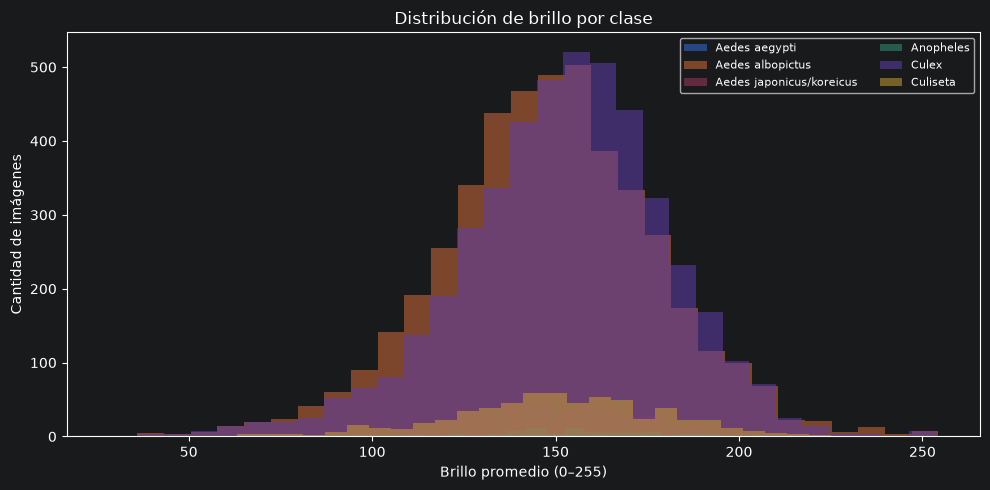

In [43]:
plt.figure(figsize=(10, 5))
for clase, grupo in df_validas.groupby("Clase"):
    plt.hist(grupo["Brillo"].dropna(), bins=30, alpha=0.55, label=clase)
plt.title("Distribución de brillo por clase")
plt.xlabel("Brillo promedio (0–255)")
plt.ylabel("Cantidad de imágenes")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 17. Distribución del contraste por clase

Se analizan las diferencias de contraste entre especies. Los valores bajos pueden dificultar la distinción visual de detalles, aunque dependen de cada fotografía.

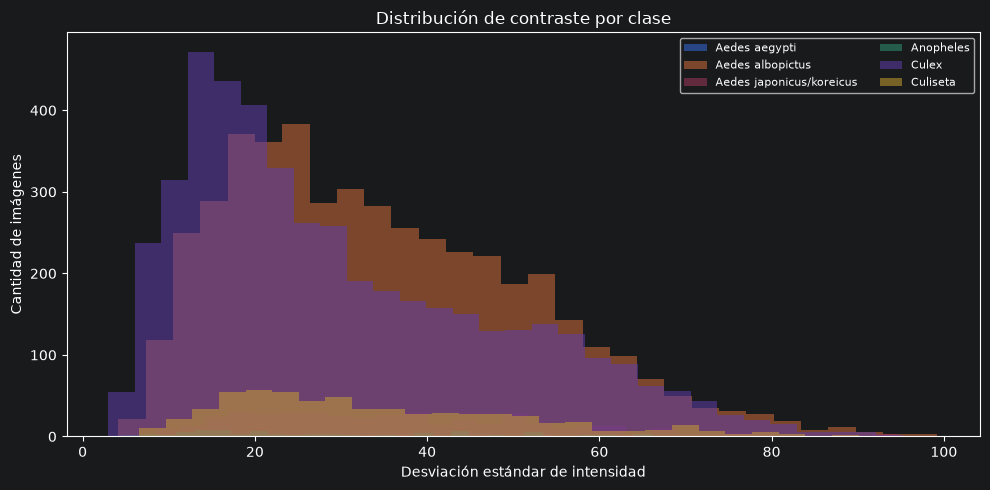

In [44]:
plt.figure(figsize=(10, 5))
for clase, grupo in df_validas.groupby("Clase"):
    plt.hist(grupo["Contraste"].dropna(), bins=30, alpha=0.55, label=clase)
plt.title("Distribución de contraste por clase")
plt.xlabel("Desviación estándar de intensidad")
plt.ylabel("Cantidad de imágenes")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 18. Análisis de nitidez por clase

Se utiliza la **varianza del Laplaciano** sobre imágenes reducidas a 128 × 128 píxeles. Los valores bajos pueden indicar desenfoque, pero también responden al contenido visual, ruido y fondo de la imagen.

,count,mean,std,min,25%,50%,75%,max
Clase,,,,,,,,
Aedes aegypti,47.0,1038.99,1448.26,36.79,283.51,501.72,1168.39,7543.62
Aedes albopictus,4612.0,441.55,626.87,8.10,141.53,254.68,475.79,8268.37
Aedes japonicus/koreicus,429.0,587.91,666.00,18.80,187.03,339.18,766.32,5804.02
Anopheles,84.0,341.97,432.15,11.90,129.17,221.24,336.89,2574.27
Culex,4563.0,365.90,677.25,6.06,81.80,185.07,389.79,14783.39
Culiseta,622.0,521.59,648.77,18.06,170.46,305.31,626.64,6675.65


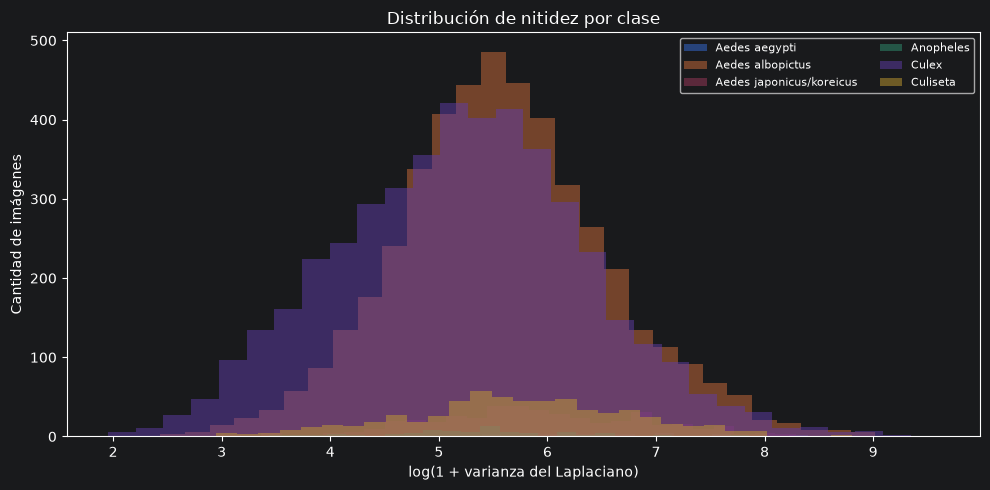

In [45]:
display(df_validas.groupby("Clase")["Nitidez"].describe().round(2))

plt.figure(figsize=(10, 5))
for clase, grupo in df_validas.groupby("Clase"):
    plt.hist(np.log1p(grupo["Nitidez"].dropna()), bins=30, alpha=0.50, label=clase)
plt.title("Distribución de nitidez por clase")
plt.xlabel("log(1 + varianza del Laplaciano)")
plt.ylabel("Cantidad de imágenes")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 19. Revisión visual de imágenes con menor nitidez

Se visualizan las imágenes con menor varianza del Laplaciano para revisar si realmente presentan desenfoque. No se eliminan fotografías en esta etapa.

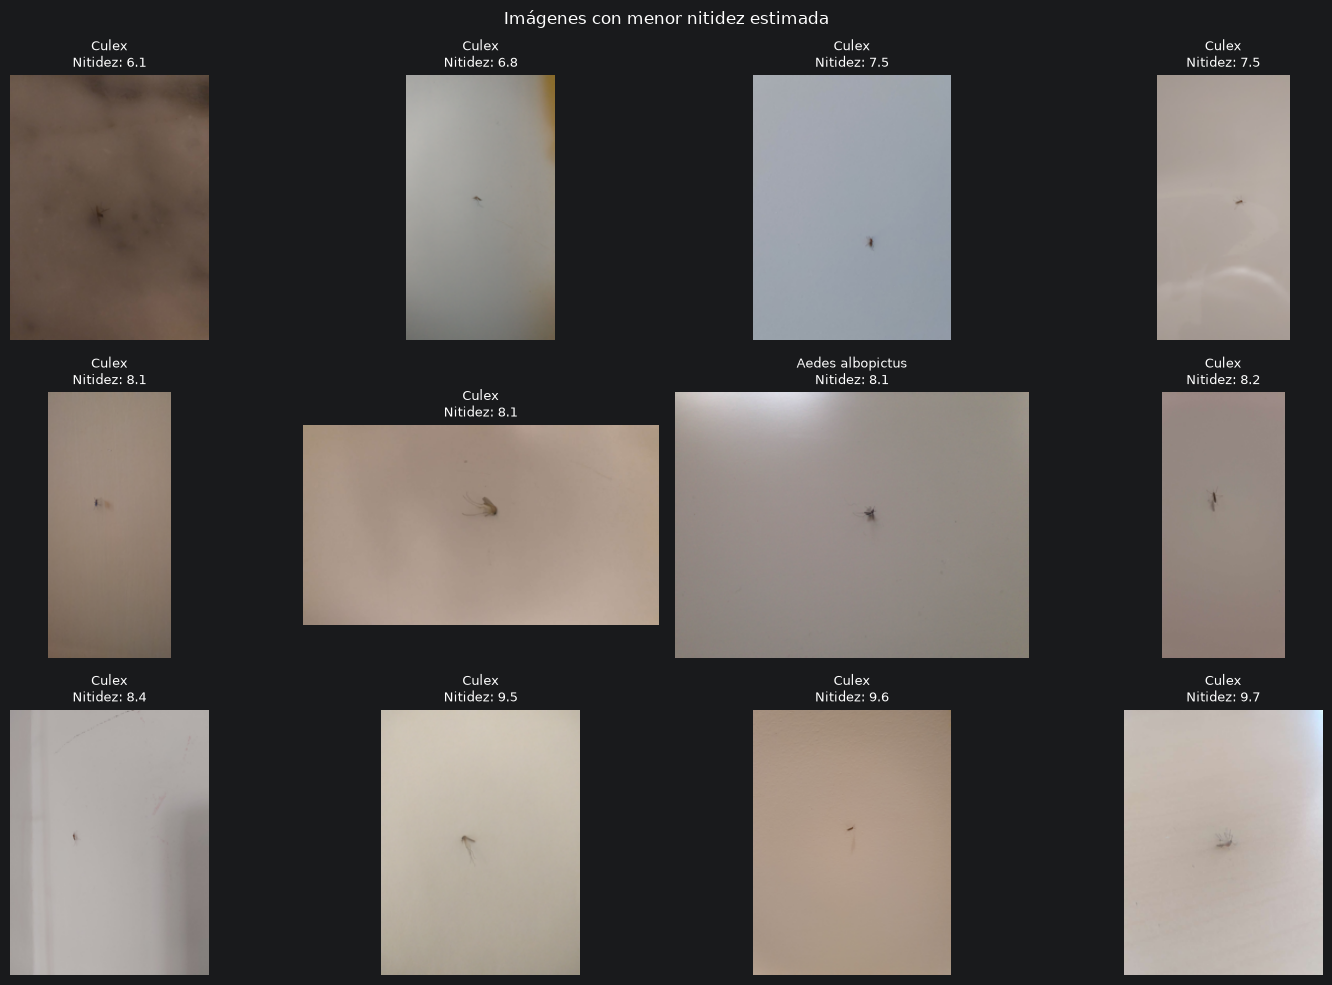

In [46]:
muestra_nitidez = df_validas.nsmallest(min(12, len(df_validas)), "Nitidez")
fig, ejes = plt.subplots(3, 4, figsize=(15, 10), squeeze=False)

for eje, (_, fila) in zip(ejes.flat, muestra_nitidez.iterrows()):
    with Image.open(fila["Ruta"]) as img:
        imagen = ImageOps.exif_transpose(img).convert("RGB")
        imagen.thumbnail((320, 240))
        eje.imshow(imagen)
    eje.set_title(f'{fila["Clase"]}\nNitidez: {fila["Nitidez"]:.1f}', fontsize=9)
    eje.axis("off")

for eje in ejes.flat[len(muestra_nitidez):]:
    eje.axis("off")

plt.suptitle("Imágenes con menor nitidez estimada")
plt.tight_layout()
plt.show()

## 20. Validación de cajas delimitadoras (bounding boxes)

Se revisan las coordenadas de las anotaciones para detectar cajas fuera de la imagen, dimensiones negativas o información ausente. También se comparan las dimensiones declaradas en el CSV con las dimensiones reales de las imágenes asociadas.

In [47]:
columnas_numericas = ["img_w", "img_h", "bbx_xtl", "bbx_ytl", "bbx_xbr", "bbx_ybr"]
df_cajas = anotaciones.copy()
for columna in columnas_numericas:
    df_cajas[columna] = pd.to_numeric(df_cajas[columna], errors="coerce")

df_cajas["Caja válida"] = (
    df_cajas[columnas_numericas].notna().all(axis=1)
    & (df_cajas["img_w"] > 0) & (df_cajas["img_h"] > 0)
    & (df_cajas["bbx_xtl"] >= 0) & (df_cajas["bbx_ytl"] >= 0)
    & (df_cajas["bbx_xbr"] > df_cajas["bbx_xtl"])
    & (df_cajas["bbx_ybr"] > df_cajas["bbx_ytl"])
    & (df_cajas["bbx_xbr"] <= df_cajas["img_w"])
    & (df_cajas["bbx_ybr"] <= df_cajas["img_h"])
)

df_cajas = df_cajas.merge(
    df_validas[["Ruta", "Ancho", "Alto"]], on="Ruta", how="left"
)
df_cajas["Dimensiones coinciden"] = (
    df_cajas["Ancho"].eq(df_cajas["img_w"])
    & df_cajas["Alto"].eq(df_cajas["img_h"])
)

comparables = df_cajas["Ruta"].notna() & df_cajas["Ancho"].notna()
diferencias_dimensiones = comparables & ~df_cajas["Dimensiones coinciden"]

print("Anotaciones revisadas:", len(df_cajas))
print("Cajas válidas:", int(df_cajas["Caja válida"].sum()))
print("Cajas inválidas:", int((~df_cajas["Caja válida"]).sum()))
print("Diferencias de tamaño CSV vs imagen:", int(diferencias_dimensiones.sum()))
display(df_cajas.loc[~df_cajas["Caja válida"], ["img_fName", "Clase", *columnas_numericas]].head(10))

Anotaciones revisadas: 10357
Cajas válidas: 10354
Cajas inválidas: 3
Diferencias de tamaño CSV vs imagen: 0


,img_fName,Clase,img_w,img_h,bbx_xtl,bbx_ytl,bbx_xbr,bbx_ybr
9004,train_09004.jpeg,Culex,1024,1365,435,233,1159,650
10156,train_10156.jpeg,Aedes albopictus,1024,2272,1070,512,1312,845
10160,train_10160.jpeg,Culex,1816,4032,1755,522,2345,964


## 21. Tamaño relativo de los mosquitos en las fotografías

A partir de las cajas válidas se calcula qué porcentaje del ancho, alto y superficie de la imagen ocupa cada mosquito. Esto permite detectar fotografías donde el mosquito es muy pequeño respecto al fondo.

Ancho relativo (%)                                    \
                                      count   mean    std   min    25%    50%   
Clase                                                                           
Aedes aegypti                          47.0  50.24  28.04  9.38  22.14  48.98   
Aedes albopictus                     4611.0  33.42  20.39  2.54  17.13  28.12   
Aedes japonicus/koreicus              429.0  41.67  21.23  6.35  24.22  38.86   
Anopheles                              84.0  39.64  20.17  9.00  22.97  36.61   
Culex                                4561.0  33.54  19.30  0.03  17.97  28.44   
Culiseta                              622.0  43.48  22.51  8.70  24.27  38.93   

                                        Alto relativo (%)         ...         \
                            75%     max             count   mean  ...    75%   
Clase                                                             ...          
Aedes aegypti             74.61   95.67              47.0  44.98  ...  68.54   
Aedes albopictus          44.94  100.00            4611.0  29.38  ...  40.00   
Aedes japonicus/koreicus  55.74   97.46             429.0  35.56  ...  48.32   
Anopheles                 50.35   90.62              84.0  32.09  ...  41.49   
Culex                     44.74  100.00            4561.0  28.10  ...  37.60   
Culiseta                  58.95  100.00             622.0  36.16  ...  48.96   

                                 Área relativa (%)                            \
                             max             count   mean    std   min   25%   
Clase                                                                          
Aedes aegypti             100.00              47.0  28.54  26.25  0.85  3.73   
Aedes albopictus           97.01            4611.0  12.79  14.73  0.12  2.45   
Aedes japonicus/koreicus   94.17             429.0  17.76  16.76  0.43  4.99   
Anopheles                  92.67              84.0  15.42  15.07  0.86  4.52   
Culex                      95.73            4561.0  12.06  13.65  0.00  2.61   
Culiseta                   95.47             622.0  18.98  17.96  0.61  4.89   

                                               
                            50%    75%    max  
Clase                                          
Aedes aegypti             28.06  41.28  95.67  
Aedes albopictus           7.04  17.42  93.95  
Aedes japonicus/koreicus  12.27  25.37  90.42  
Anopheles                 10.23  20.44  82.91  
Culex                      6.61  15.81  89.52  
Culiseta                  12.12  29.28  84.85  

[6 rows x 24 columns]

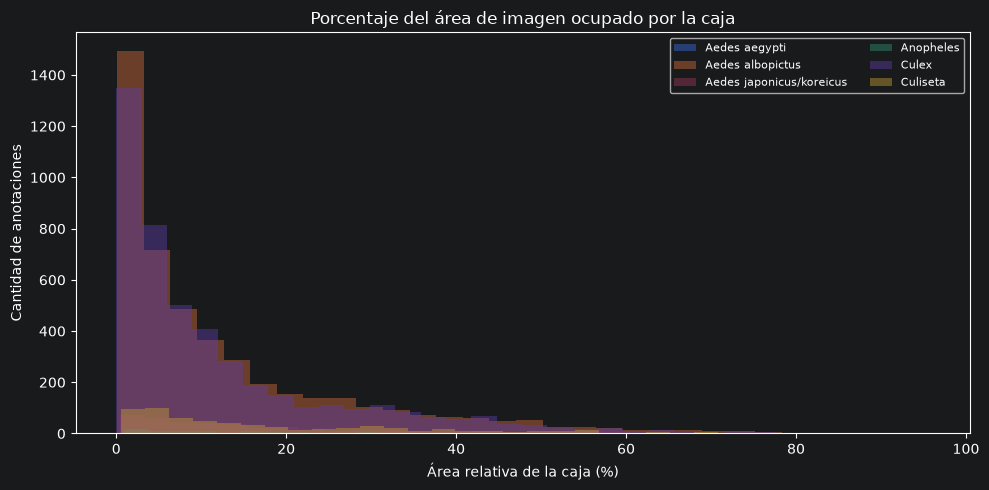

Cajas con área menor al 1 %: 462


In [48]:
cajas_validas = df_cajas.loc[df_cajas["Caja válida"]].copy()
cajas_validas["Ancho caja"] = cajas_validas["bbx_xbr"] - cajas_validas["bbx_xtl"]
cajas_validas["Alto caja"] = cajas_validas["bbx_ybr"] - cajas_validas["bbx_ytl"]
cajas_validas["Ancho relativo (%)"] = 100 * cajas_validas["Ancho caja"] / cajas_validas["img_w"]
cajas_validas["Alto relativo (%)"] = 100 * cajas_validas["Alto caja"] / cajas_validas["img_h"]
cajas_validas["Área relativa (%)"] = (
    100 * cajas_validas["Ancho caja"] * cajas_validas["Alto caja"]
    / (cajas_validas["img_w"] * cajas_validas["img_h"])
)

display(cajas_validas.groupby("Clase")[
    ["Ancho relativo (%)", "Alto relativo (%)", "Área relativa (%)"]
].describe().round(2))

plt.figure(figsize=(10, 5))
for clase, grupo in cajas_validas.groupby("Clase"):
    plt.hist(grupo["Área relativa (%)"], bins=30, alpha=0.45, label=clase)
plt.title("Porcentaje del área de imagen ocupado por la caja")
plt.xlabel("Área relativa de la caja (%)")
plt.ylabel("Cantidad de anotaciones")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

print("Cajas con área menor al 1 %:", int((cajas_validas["Área relativa (%)"] < 1).sum()))

## 22. Visualización de ejemplos con cajas delimitadoras

Se muestran ejemplos anotados con sus cajas oficiales para comprobar de forma visual la relación entre fotografía y etiqueta. Las coordenadas se ajustan al tamaño mostrado, **sin modificar el archivo original**.

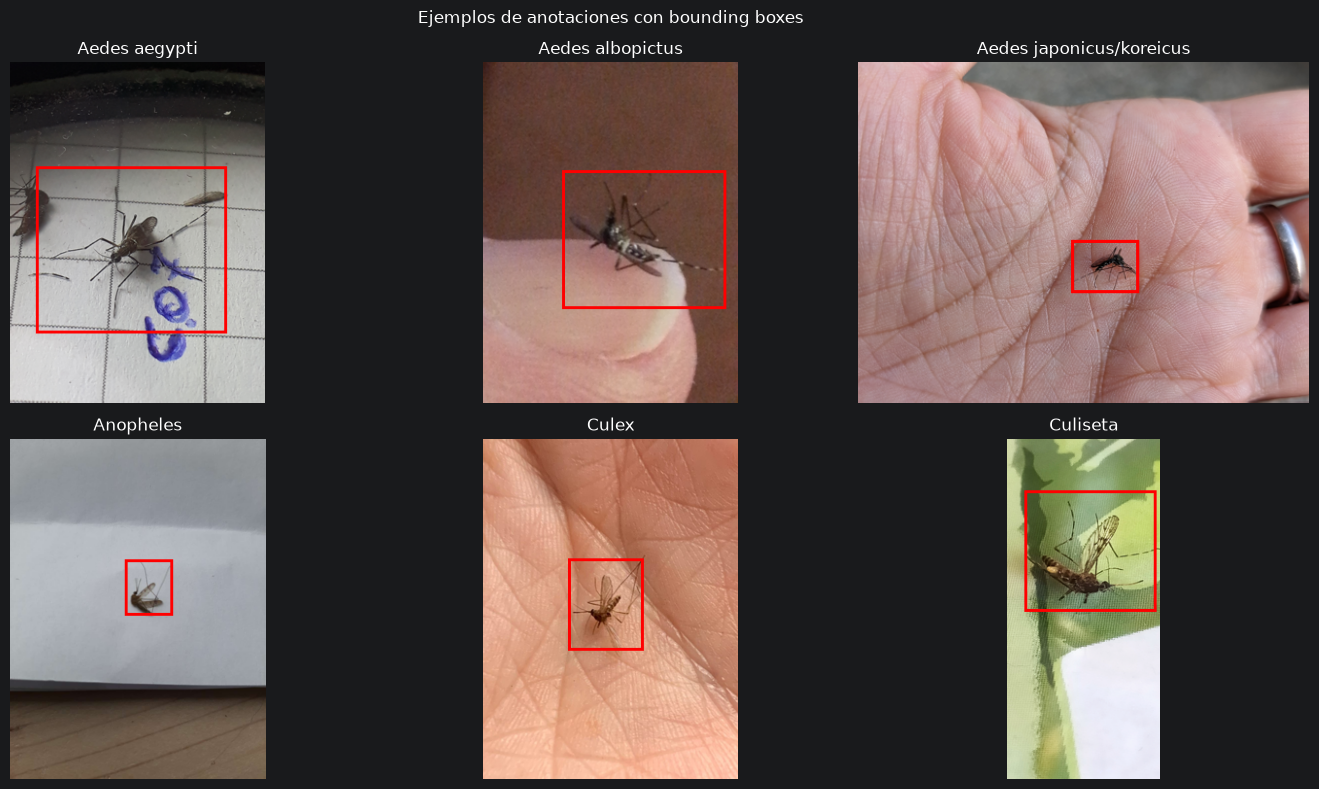

In [49]:
muestras_cajas = (
    cajas_validas.dropna(subset=["Ruta"])
    .groupby("Clase", group_keys=False)
    .sample(n=1, random_state=42)
    .reset_index(drop=True)
)

if muestras_cajas.empty:
    print("No hay cajas válidas asociadas a imágenes para visualizar.")
else:
    columnas = 3
    filas = int(np.ceil(len(muestras_cajas) / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=(15, filas * 4), squeeze=False)

    for eje, (_, fila) in zip(ejes.flat, muestras_cajas.iterrows()):
        with Image.open(fila["Ruta"]) as img:
            original_ancho, original_alto = img.size
            imagen = img.convert("RGB")
            imagen.thumbnail((430, 350))
            escala_x = imagen.width / original_ancho
            escala_y = imagen.height / original_alto
            dibujo = ImageDraw.Draw(imagen)
            dibujo.rectangle(
                [
                    fila["bbx_xtl"] * escala_x,
                    fila["bbx_ytl"] * escala_y,
                    fila["bbx_xbr"] * escala_x,
                    fila["bbx_ybr"] * escala_y,
                ],
                outline="red", width=3,
            )
            eje.imshow(imagen)
        eje.set_title(fila["Clase"])
        eje.axis("off")

    for eje in ejes.flat[len(muestras_cajas):]:
        eje.axis("off")
    plt.suptitle("Ejemplos de anotaciones con bounding boxes")
    plt.tight_layout()
    plt.show()

## 23. Detección de archivos exactamente duplicados (SHA-256)

Se calculan hashes SHA-256 para encontrar archivos con contenido binario idéntico. La lectura se hace en bloques y no carga el dataset completo en memoria. Este proceso lee todos los archivos válidos y es independiente de la semejanza visual.

In [50]:
def calcular_sha256(archivo):
    hash_archivo = hashlib.sha256()
    with open(archivo, "rb") as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b""):
            hash_archivo.update(bloque)
    return hash_archivo.hexdigest()

hashes = []
for i, archivo in enumerate(df_validas["Ruta"], start=1):
    hashes.append(calcular_sha256(archivo))
    if i % 2000 == 0:
        print(f"Hashes calculados: {i} de {len(df_validas)}")

df_hash = df_validas[["Ruta", "Clase"]].copy()
df_hash["SHA256"] = hashes

duplicados_sha = df_hash[df_hash.duplicated("SHA256", keep=False)].sort_values("SHA256")
duplicados_adicionales = int(df_hash.duplicated("SHA256", keep="first").sum())
conflictos = df_hash.groupby("SHA256")["Clase"].nunique().loc[lambda serie: serie > 1]

print("Imágenes válidas:", len(df_hash))
print("Duplicados exactos adicionales:", duplicados_adicionales)
print("Imágenes únicas (SHA-256):", df_hash["SHA256"].nunique())
print("Grupos de duplicados con etiquetas diferentes:", len(conflictos))
display(duplicados_sha[["Clase", "Ruta", "SHA256"]].head(20))

Hashes calculados: 2000 de 10357
Hashes calculados: 4000 de 10357
Hashes calculados: 6000 de 10357
Hashes calculados: 8000 de 10357
Hashes calculados: 10000 de 10357
Imágenes válidas: 10357
Duplicados exactos adicionales: 44
Imágenes únicas (SHA-256): 10313
Grupos de duplicados con etiquetas diferentes: 0


,Clase,Ruta,SHA256
8081,Aedes albopictus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,098553d6d93362a6bdce4ee79f4ede154a6cf80178167a...
7899,Aedes albopictus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,098553d6d93362a6bdce4ee79f4ede154a6cf80178167a...
8730,Culex,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,11b9e9a18f6e48fe15d48534ddbc45a2b63c753e3aa75d...
6200,Culex,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,11b9e9a18f6e48fe15d48534ddbc45a2b63c753e3aa75d...
8602,Aedes albopictus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,1970f1454cd53e5788bcd1c8eb812c4e3f0aa08d951b41...
1325,Aedes albopictus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,1970f1454cd53e5788bcd1c8eb812c4e3f0aa08d951b41...
152,Aedes albopictus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,1f75dd6556fbe3d9586ff1d36ef306fa0bf2e2a758d276...
2315,Aedes albopictus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,1f75dd6556fbe3d9586ff1d36ef306fa0bf2e2a758d276...
4072,Aedes albopictus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,21e9f7a731fddaceee804dac39d80e883aad360d767cf9...
8675,Aedes albopictus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,21e9f7a731fddaceee804dac39d80e883aad360d767cf9...


## 24. Detección de posibles duplicados visuales (dHash)

Se comparan hashes perceptuales de miniaturas. **Los dHash idénticos son candidatos a revisión**, no una confirmación de que dos fotografías sean la misma. Se excluyen los duplicados binarios ya detectados con SHA-256.

In [51]:
df_perceptual = df_validas[["Ruta", "Clase", "dHash"]].merge(
    df_hash[["Ruta", "SHA256"]], on="Ruta", how="left"
)
df_perceptual = df_perceptual.drop_duplicates("SHA256")

candidatos_visuales = df_perceptual[
    df_perceptual.duplicated("dHash", keep=False)
].sort_values("dHash")

print("Candidatos con dHash coincidente:", len(candidatos_visuales))
print("Grupos de dHash coincidente:", candidatos_visuales["dHash"].nunique())
display(candidatos_visuales[["Clase", "Ruta", "dHash"]].head(20))

Candidatos con dHash coincidente: 136
Grupos de dHash coincidente: 42


,Clase,Ruta,dHash
5224,Aedes albopictus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,0000000000000000000000000000000000000000000000...
3293,Aedes albopictus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,0000000000000000000000000000000000000000000000...
3779,Culex,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,0000000000000000000000000000000000000000000000...
4037,Culex,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,0000000000000000000000000000000000000000000000...
8708,Culex,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,0000000000000000000000000000000000000000000000...
804,Culex,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,0000000000000000000000000000000000000000000000...
8057,Culex,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,0000000000000000000000000000000000000000000000...
906,Culex,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,0000000000000000000000000000000000000000000000...
7652,Aedes albopictus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,0000000000000000000000000000000000000000000000...
7097,Aedes albopictus,C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2...,0000000000000000000000000000000000000000000000...


## 25. Evaluación del desbalance entre clases

Se compara la frecuencia de las especies y la relación entre las clases con mayor y menor cantidad de anotaciones. La recomendación de balanceo debe considerar el objetivo final de VectorIA: **Aedes aegypti, Aedes albopictus y Culex**.

Clase mayoritaria: Aedes albopictus (4612 anotaciones)
Clase minoritaria: Aedes aegypti (47 anotaciones)
Relación de desbalance: 98.13:1


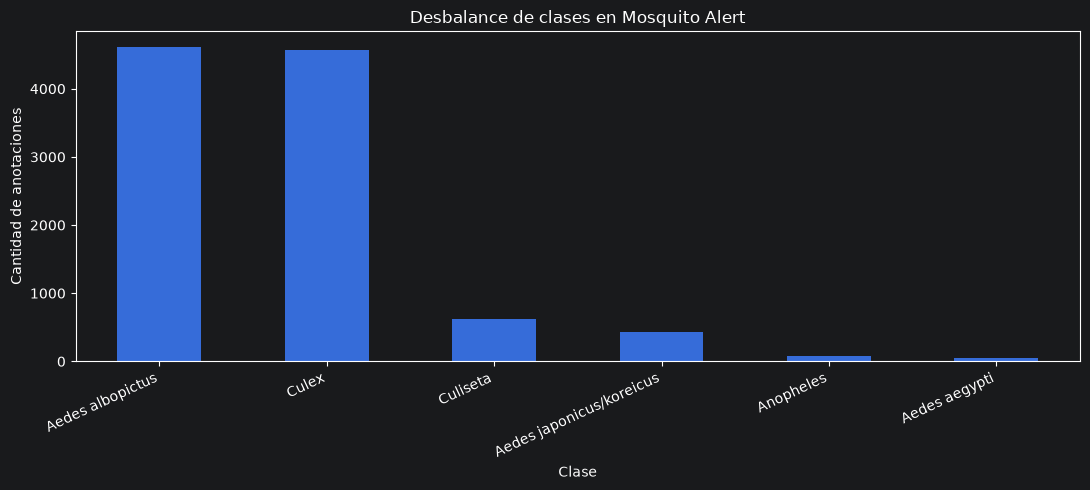

In [52]:
conteos = tabla_conteo.set_index("Clase")["Anotaciones"].sort_values(ascending=False)
mayor, menor = int(conteos.max()), int(conteos.min())
relacion_desbalance = mayor / menor if menor > 0 else np.nan

print("Clase mayoritaria:", conteos.index[0], f"({mayor} anotaciones)")
print("Clase minoritaria:", conteos.index[-1], f"({menor} anotaciones)")
print(f"Relación de desbalance: {relacion_desbalance:.2f}:1")

plt.figure(figsize=(11, 5))
conteos.plot(kind="bar")
plt.title("Desbalance de clases en Mosquito Alert")
plt.xlabel("Clase")
plt.ylabel("Cantidad de anotaciones")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 26. Revisión de las clases útiles para VectorIA

Se diferencia entre las clases disponibles en el dataset y las tres clases solicitadas para el modelo final. **Aedes** no debe fusionarse automáticamente con una especie concreta: se deben conservar las etiquetas originales y decidir el mapeo en la preparación de datos.

In [53]:
clases_objetivo = {"Aedes aegypti", "Aedes albopictus", "Culex"}
tabla_objetivo = tabla_conteo[["Clase", "Anotaciones", "Imágenes únicas"]].copy()
tabla_objetivo["Uso en CNN de 3 clases"] = tabla_objetivo["Clase"].apply(
    lambda clase: "Clase objetivo" if clase in clases_objetivo else "Fuera de las 3 clases objetivo"
)
display(tabla_objetivo)

print("Anotaciones de las tres clases objetivo:", int(
    tabla_objetivo.loc[
        tabla_objetivo["Clase"].isin(clases_objetivo), "Anotaciones"
    ].sum()
))

,Clase,Anotaciones,Imágenes únicas,Uso en CNN de 3 clases
1,Aedes albopictus,4612,4612,Clase objetivo
4,Culex,4563,4563,Clase objetivo
5,Culiseta,622,622,Fuera de las 3 clases objetivo
2,Aedes japonicus/koreicus,429,429,Fuera de las 3 clases objetivo
3,Anopheles,84,84,Fuera de las 3 clases objetivo
0,Aedes aegypti,47,47,Clase objetivo


Anotaciones de las tres clases objetivo: 9222


## 27. Resumen automático del EDA

Se recopilan las principales métricas reales obtenidas en los análisis anteriores. Este resumen servirá para redactar la conclusión final después de ejecutar todas las celdas.

In [54]:
resumen = pd.DataFrame([
    ("Total de imágenes encontradas", len(inventario)),
    ("Total de anotaciones del CSV", len(anotaciones)),
    ("Clases identificadas", anotaciones["Clase"].nunique()),
    ("Anotaciones asociadas a imágenes", int(anotaciones["Ruta"].notna().sum())),
    ("Anotaciones sin imagen asociada", int(anotaciones["Ruta"].isna().sum())),
    ("Imágenes sin anotación", int((inventario["Clase"] == "Sin etiqueta").sum())),
    ("Imágenes válidas", len(df_validas)),
    ("Imágenes dañadas", len(df_danadas)),
    ("Resoluciones diferentes", len(resoluciones)),
    ("Modos de color diferentes", df_validas["Modo de color"].nunique()),
    ("Formatos reales diferentes", df_validas["Formato real"].nunique()),
    ("Formatos inconsistentes", len(inconsistencias_formato)),
    ("Anotaciones con caja válida", int(df_cajas["Caja válida"].sum())),
    ("Anotaciones con caja inválida", int((~df_cajas["Caja válida"]).sum())),
    ("Diferencias de dimensiones CSV-imagen", int(diferencias_dimensiones.sum())),
    ("Cajas que ocupan menos del 1 %", int((cajas_validas["Área relativa (%)"] < 1).sum())),
    ("Duplicados exactos adicionales", duplicados_adicionales),
    ("Grupos de duplicados con etiquetas distintas", len(conflictos)),
    ("Candidatos visualmente repetidos (dHash)", len(candidatos_visuales)),
    ("Brillo medio", round(df_validas["Brillo"].mean(), 2)),
    ("Contraste medio", round(df_validas["Contraste"].mean(), 2)),
    ("Nitidez mediana", round(df_validas["Nitidez"].median(), 2)),
    ("Relación entre clase mayoritaria y minoritaria", round(relacion_desbalance, 2)),
], columns=["Indicador", "Resultado"])

display(resumen)
print("\nDISTRIBUCIÓN POR CLASE:")
display(tabla_conteo)


,Indicador,Resultado
0,Total de imágenes encontradas,10357.00
1,Total de anotaciones del CSV,10357.00
2,Clases identificadas,6.00
3,Anotaciones asociadas a imágenes,10357.00
4,Anotaciones sin imagen asociada,0.00
5,Imágenes sin anotación,0.00
6,Imágenes válidas,10357.00
7,Imágenes dañadas,0.00
8,Resoluciones diferentes,2116.00
9,Modos de color diferentes,1.00



DISTRIBUCIÓN POR CLASE:


,Clase,Anotaciones,Imágenes únicas,Porcentaje de anotaciones (%)
1,Aedes albopictus,4612,4612,44.53
4,Culex,4563,4563,44.06
5,Culiseta,622,622,6.01
2,Aedes japonicus/koreicus,429,429,4.14
3,Anopheles,84,84,0.81
0,Aedes aegypti,47,47,0.45



## 28. Conclusiones generales del EDA

El análisis exploratorio del dataset Mosquito Alert 2023 permitió evaluar las características, distribución, calidad e integridad de las imágenes y sus anotaciones, identificando aspectos importantes que deben considerarse antes del entrenamiento de la CNN del proyecto VectorIA.

### 28.1. Principales hallazgos

1. **Cantidad de imágenes:** se analizaron 10.357 imágenes correspondientes a seis clases de mosquitos. Todas las imágenes cuentan con una anotación asociada, sin registros faltantes.

2. **Distribución de clases:** las especies Aedes albopictus (44,53 %) y Culex (44,06 %) representan la mayor parte del dataset. En cambio, Aedes aegypti cuenta únicamente con 47 imágenes (0,45 %), lo que evidencia una representación muy reducida de esta especie.

3. **Desbalance de clases:** se identificó una relación de 98,13:1 entre la clase mayoritaria y la minoritaria. Este desbalance es considerable y podría provocar que la CNN favorezca las especies con mayor cantidad de imágenes, especialmente al clasificar Aedes aegypti.

4. **Dimensiones:** se encontraron 2.116 resoluciones diferentes. Esto demuestra que las imágenes no tienen dimensiones uniformes y necesitarán ser redimensionadas antes del entrenamiento.

5. **Formatos y canales de color:** se identificó un único formato real y un único modo de color, sin inconsistencias detectadas. Esto favorece la uniformidad del procesamiento.

6. **Brillo:** el brillo promedio fue de 150,10 en una escala de 0 a 255. La mayoría de las imágenes presenta valores intermedios de iluminación, aunque existen fotografías considerablemente más oscuras o claras.

7. **Contraste:** se obtuvo un contraste promedio de 32,74. Los gráficos muestran variaciones entre las imágenes y las clases, aunque las distribuciones de Aedes albopictus y Culex presentan una superposición importante.

8. **Nitidez:** la mediana de nitidez fue de 234,87, calculada mediante la varianza del Laplaciano. Se identificó variabilidad en los niveles de detalle de las fotografías, por lo que resulta conveniente revisar los casos con valores extremos.

9. **Integridad:** las 10.357 imágenes pudieron procesarse correctamente, sin encontrar archivos dañados.

10. **Duplicados:** se identificaron 44 duplicados exactos adicionales y 136 candidatos a imágenes visualmente similares mediante dHash. Estos últimos requieren revisión, ya que una similitud visual no demuestra necesariamente que sean duplicados.

11. **Anotaciones:** se identificaron 10.354 cajas delimitadoras válidas y 3 inválidas. Además, no se encontraron diferencias entre las dimensiones registradas en el CSV y las dimensiones reales de las imágenes.

12. **Tamaño de los objetos:** se encontraron 462 cajas delimitadoras que ocupan menos del 1 % de sus respectivas imágenes. Esto indica que algunos mosquitos aparecen muy pequeños dentro de las fotografías, lo que podría dificultar su identificación.

13. **Tamaño de archivos:** las imágenes presentan tamaños de almacenamiento variables. La mayoría corresponde a archivos relativamente pequeños, aunque existen fotografías considerablemente más pesadas.

### 28.2. Recomendaciones para el entrenamiento

- **Balanceo de clases:** aplicar estrategias como ponderación de clases, aumento de datos o muestreo para reducir el efecto del desbalance, especialmente en Aedes aegypti.

- **Complementar imágenes:** incorporar fotografías de Aedes aegypti procedentes de IEEE DataPort, Mendeley o Kaggle, verificando que las etiquetas correspondan realmente a la especie requerida.

- **Estandarizar dimensiones:** redimensionar las imágenes a 128 × 128 píxeles para la CNN propuesta, considerando métodos que permitan conservar las características visuales del mosquito.

- **Revisar duplicados:** identificar y gestionar los 44 duplicados exactos, además de revisar los 136 candidatos visualmente similares antes de dividir los datos en entrenamiento, validación y prueba.

- **Corregir anotaciones:** revisar las 3 cajas delimitadoras inválidas para evitar problemas durante el procesamiento.

- **Revisar objetos pequeños:** inspeccionar las 462 imágenes con cajas que ocupan menos del 1 % del área, considerando el recorte del mosquito cuando sea apropiado.

- **Evaluar calidad visual:** revisar fotografías con valores extremos de brillo, contraste y nitidez para determinar si requieren algún tratamiento adicional.

- **Seleccionar las clases necesarias:** para la CNN principal de VectorIA se necesitan Aedes aegypti, Aedes albopictus y Culex. Las otras tres clases deberán gestionarse por separado según el objetivo del modelo.

- **Evitar fugas de información:** separar correctamente entrenamiento, validación y prueba, evitando que imágenes idénticas o derivadas de una misma fotografía aparezcan en conjuntos diferentes.

- **Evaluar por clase:** utilizar F1-score macro y analizar el rendimiento individual de cada especie, debido al fuerte desbalance del dataset.

### 28.3. Conclusión final

El dataset Mosquito Alert 2023 constituye una fuente importante de imágenes para el proyecto VectorIA, debido a su cantidad de fotografías, diversidad de especies y disponibilidad de anotaciones que permiten identificar la ubicación de los mosquitos.

El análisis confirmó que las imágenes presentan una adecuada integridad general, sin archivos dañados ni anotaciones faltantes. Sin embargo, se identificaron aspectos que requieren atención, principalmente el fuerte desbalance entre clases, la diversidad de resoluciones, los archivos duplicados y algunas inconsistencias en las cajas delimitadoras.

La principal limitación del dataset es la escasa representación de Aedes aegypti, con únicamente 47 imágenes frente a las 4.612 de Aedes albopictus y las 4.563 de Culex. Esta diferencia podría afectar significativamente la capacidad del modelo para reconocer correctamente la especie minoritaria.

Por lo tanto, se recomienda utilizar este dataset en combinación con las demás fuentes de imágenes del proyecto, aplicar las técnicas de preprocesamiento necesarias y establecer una estrategia de evaluación que considere el desbalance.

En conclusión, el dataset es útil para el desarrollo de la CNN, pero requiere una preparación cuidadosa antes del entrenamiento para reducir posibles sesgos y mejorar la capacidad de generalización del modelo.
